# Reliability Analysis

The purpose of this notebook is to explore different methods of computing if a cell is good or not. I have observed that in the current analysis, some cells turn out to be reliable when in fact they don't visually look like it, leading to some false positives (still to be negatives)

Current methods of computing reliability:
1. For an iteration, I take all the trials and divide them in two random halves
2. Then, I take the mean of each of them and compute the correlation between them, this is the true correlation
3. I shuffle the trials and compute the correlation between the two halves, this is the shuffled correlation
4. I repeat this process for n_iterations
5. The cell is deemed reliable when the true correlation is greater than the 99th percentile of the shuffled correlation

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from DistanceProject import DistanceAnalysis, create_new_result_dir
from DistancePlots import *
import os
import pickle

%load_ext autoreload
%autoreload 2

data_dir = r'D:/data-distance-coding-project/processed-data'

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [3]:
imaging_filename = r'240731_SAM019_1'

imaging_dir = os.path.join(data_dir, imaging_filename)
result_dir = data_dir + '/' + str(imaging_filename) + '/results'
object_filename = imaging_dir + '/' + imaging_filename + '_distance.pkl'

if os.path.exists(object_filename):
    with open(object_filename, 'rb') as f:
        D = pickle.load(f)
        print('Loaded DistanceAnalysis object')
else:
    D = DistanceAnalysis(imaging_dir, angle_range = np.linspace(-40, 60, 100), activity_mode='dFF', run_session=True, n_iterations=100)

Loaded DistanceAnalysis object


# Example of a cell that I don't like using this method

KstestResult(statistic=1.0, pvalue=0.0, statistic_location=0.8496251660676746, statistic_sign=1)
3.3797731655950987


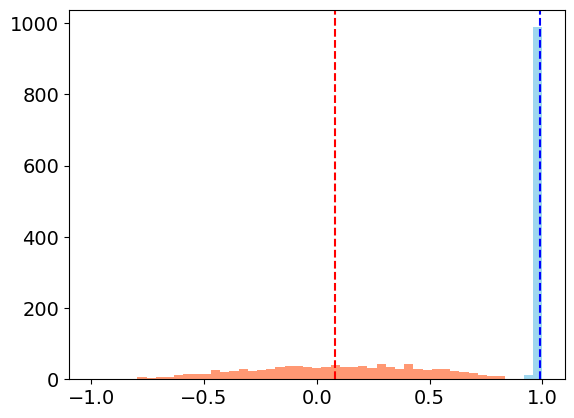

In [65]:
from scipy import stats

D.activity_mode = 'spikes'
is_reliable, reliability, corr_shifted, corr_real = D.compute_reliability(cell=350, n_iterations=1000, block='two eye')

stats = stats.kstest(corr_shifted, corr_real)
print(stats)

plt.figure()
bins = np.linspace(-1, 1, 50)

# plot corr_real and shifted in the same histogram
plt.hist(corr_shifted, bins, alpha=0.8, label='Shuffled', color='coral')
plt.hist(corr_real, bins, alpha=0.8, label='Real', color='skyblue')

# plot the mean lines for shuffled and real
plt.axvline(np.mean(corr_shifted), color='red', linestyle='--', label='Mean Shuffled')
plt.axvline(np.mean(corr_real), color='blue', linestyle='--', label='Mean Real')

# compute cohen d for these two distributions
mean_diff = np.mean(corr_real) - np.mean(corr_shifted)
std_diff = np.sqrt((np.std(corr_real) ** 2 + np.std(corr_shifted) ** 2) / 2)
cohen_d = mean_diff / std_diff
print(cohen_d)

Reliability non-normalized 0.9928844068679933
Is reliable True


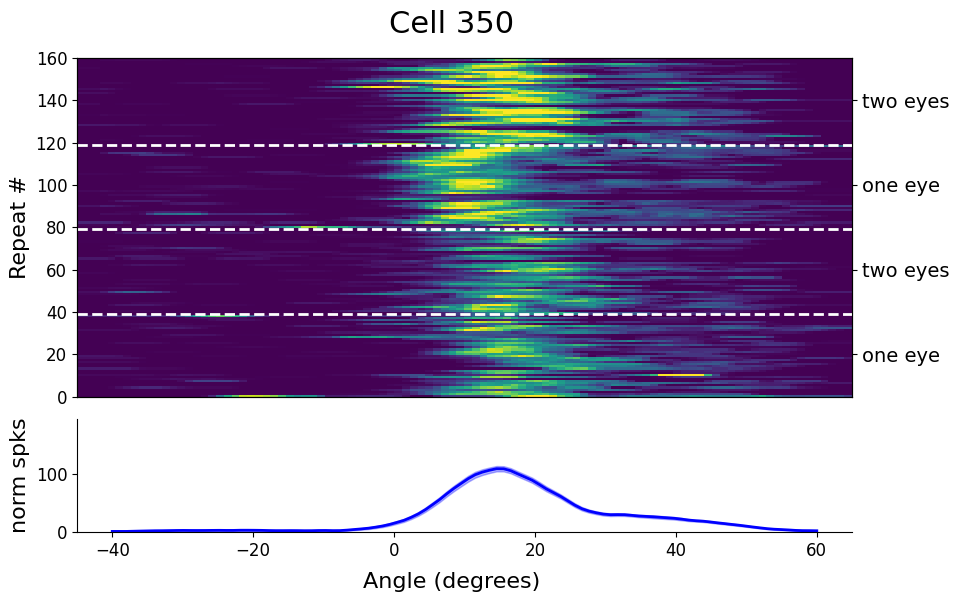

In [67]:
cell = 350
is_reliable, reliability, corr_shifted, corr_real = D.compute_reliability(cell=cell, n_iterations=200)
print('Reliability non-normalized', reliability)
print('Is reliable', is_reliable)

plot_trials(D, cell=cell)

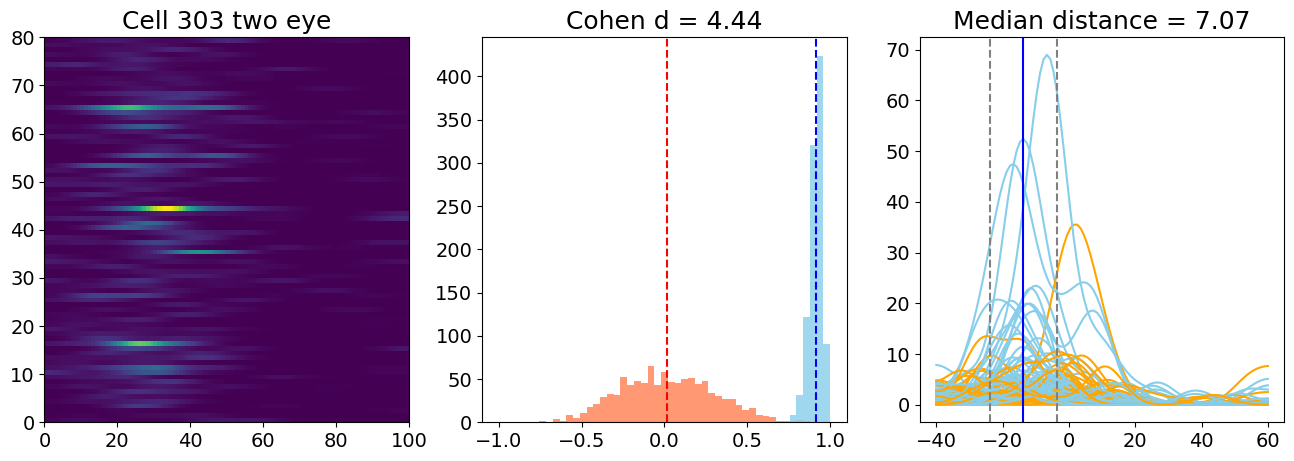

In [82]:
D.activity_mode = 'spikes'
plot_cell_reliability(D, cell=303, block='two eye', n_iterations = 1000)

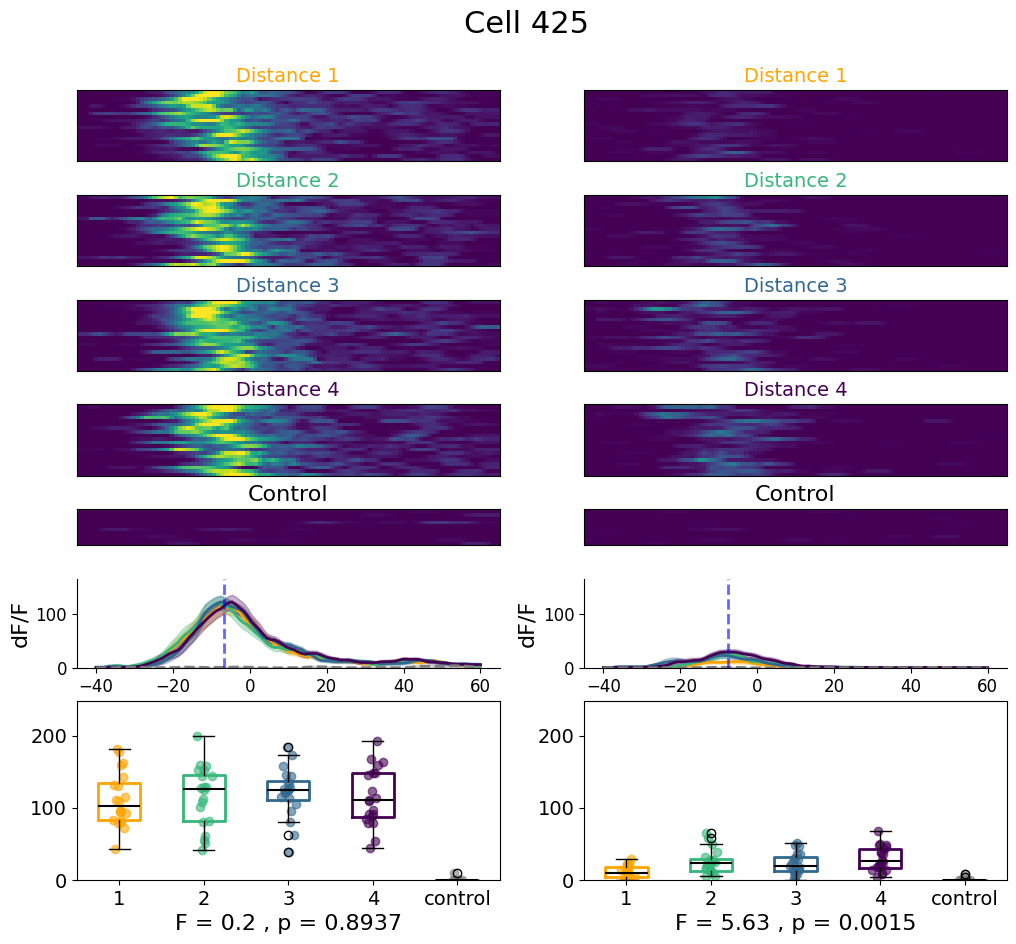

In [103]:
plot_trials_ordered_2(D, cell=425)

In [28]:
# compute cells accepted without median distance method
is_reliable_population = []
reliability_population = []
is_consistent_population = []
distance_population = []

for cell in range(D.dFF.shape[0]):
    
    is_reliable, reliability, _ = D.compute_reliability(cell=cell, n_iterations=200, additional_reliability=False, block='two eye')
    is_consistent, distance = D.is_active(cell, block='two eye')
    is_reliable_population.append(is_reliable)
    reliability_population.append(reliability)
    is_consistent_population.append(is_consistent)
    distance_population.append(distance)

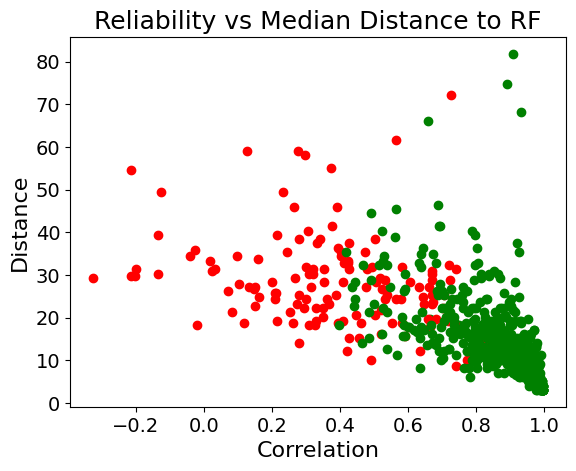

In [40]:
plt.figure()

for i in range(len(is_reliable_population)):
    if is_reliable_population[i]:
        plt.scatter(reliability_population[i], distance_population[i], color='green')
    else:
        plt.scatter(reliability_population[i], distance_population[i], color='red')
        
plt.xlabel('Correlation')
plt.ylabel('Distance')
plt.title('Reliability vs Median Distance to RF')
plt.show()
# plt.scatter(reliability_population, distance_population)

Text(0.5, 0, 'Reliability')

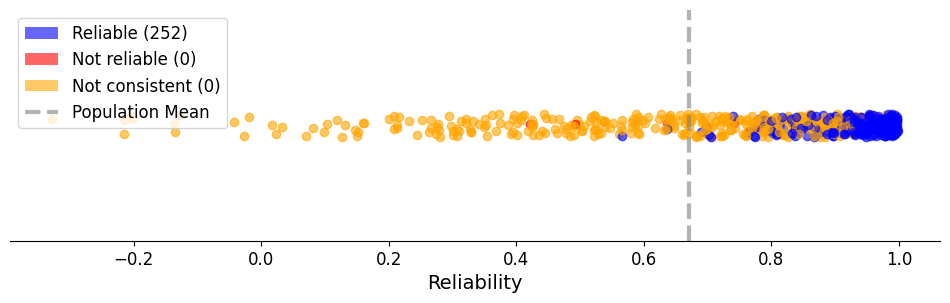

In [45]:
# percentage_reliable = 100 * np.sum(is_reliable) / len(is_reliable)
fig, ax = plt.subplots(1, 1, figsize=(12, 3))
for cell in range(len(is_reliable_population)):
    
    if is_reliable_population[cell] and is_consistent_population[cell]:
        color = 'blue'
    elif is_reliable_population and not is_consistent_population[cell]:
        color = 'orange'
    else:
        color = 'red'
    
    ax.scatter(reliability_population[cell], random.uniform(-.1, .1), color=color, alpha=0.6)

ax.set_ylim(-1, 1)
legend_elements = [Patch(facecolor='blue', alpha=0.6, label='Reliable' + r' (' + str(np.sum(is_reliable_population and is_consistent_population)) + r')'),
                   Patch(facecolor='red', alpha=0.6,
                         label='Not reliable' + r' (' + str(np.sum(np.invert(is_reliable))) + r')'),
                   Patch(facecolor='orange', alpha=0.6, label='Not consistent' + r' (' + str(np.sum(is_reliable_population and not is_consistent_population)) + r')'),
                   Line2D([0], [0], color='gray', lw=3, ls='--', alpha=0.6, label='Population Mean')]
ax.spines[['top', 'right', 'left']].set_visible(False)
ax.axvline(np.mean(reliability), ls='--', alpha=0.6, color='gray', linewidth=3)
ax.set_yticks([])
plt.xticks(fontsize=12)

ax.legend(handles=legend_elements, loc='upper left')

# if title is None:
#     ax.set_title('Reliability: ' + str(round(percentage_reliable, 2)) + '% of cells are reliable', fontsize=16)
# else:
#     ax.set_title(title + ' Reliability: ' + str(round(percentage_reliable, 2)), fontsize=16)

ax.set_xlabel('Reliability', fontsize=14)

In [46]:
# without distance method
is_reliable_one = D.stats['is_reliable_one_eye']
is_reliable_two = D.stats['is_reliable_two_eye']

is_reliable_old_two = []
is_reliable_old_one = []
for cell in range(D.dFF.shape[0]):
    # print cell in new lines
    print('Cell ' + str(cell), end='\r')
    is_reliable_old_two.append(D.compute_reliability(cell=cell, n_iterations=100, additional_reliability=False, block='two eye')[0])
    is_reliable_old_one.append(D.compute_reliability(cell=cell, n_iterations=100, additional_reliability=False, block='one eye')[0])

In [47]:
def extract_modulation(is_reliable_one, is_reliable_two):
    
    type = []
    
    for cell in range(len(is_reliable_one)):
        
        if is_reliable_one[cell] or is_reliable_two[cell]:
            
            is_monocular_modulated = D.compute_distance_modulation(cell=cell, block='one eye')[0]
            is_binocular_modulated = D.compute_distance_modulation(cell=cell, block='two eye')[0]
            
            if is_monocular_modulated and is_binocular_modulated:
                type.append('both')
            elif is_monocular_modulated:
                type.append('monocular')
            elif is_binocular_modulated:
                type.append('binocular')
            else:
                type.append('un-modulated')
            
        else:
            type.append('un-reliable')
            
    return type    

In [48]:
type_classic = extract_modulation(is_reliable_one, is_reliable_two)
type_old = extract_modulation(is_reliable_old_one, is_reliable_old_two)

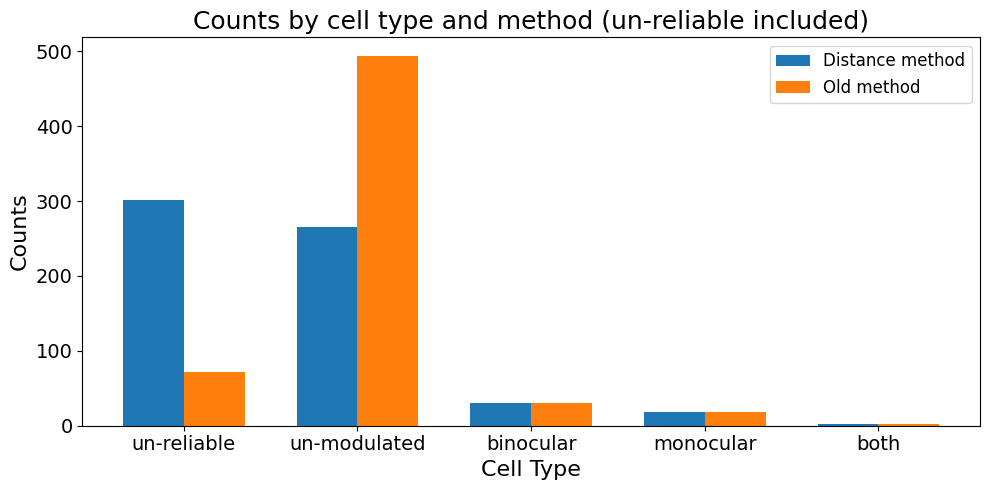

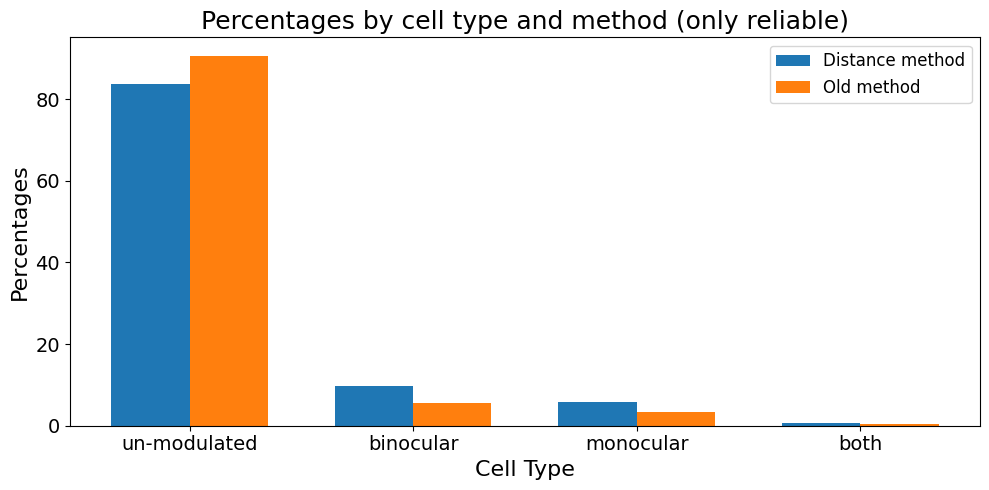

In [50]:
categories = ['un-reliable', 'un-modulated', 'binocular', 'monocular', 'both']
counts_distance = [type_classic.count(cat) for cat in categories]
counts_old= [type_old.count(cat) for cat in categories]

x = np.arange(len(categories))  # the label locations
width = 0.35  # the width of the bars

fig, ax = plt.subplots(figsize=(10, 5))
rects1 = ax.bar(x - width/2, counts_distance, width, label='Distance method')
rects2 = ax.bar(x + width/2, counts_old, width, label='Old method')

# Add some text for labels, title and custom x-axis tick labels, etc.
ax.set_xlabel('Cell Type')
ax.set_ylabel('Counts')
ax.set_title('Counts by cell type and method (un-reliable included)')
ax.set_xticks(x)
ax.set_xticklabels(categories)
ax.legend()

fig.tight_layout()

plt.show()

categories = ['un-modulated', 'binocular', 'monocular', 'both']
counts_distance = [type_classic.count(cat) for cat in categories]
counts_old= [type_old.count(cat) for cat in categories]

# Calculate percentages
total_distance = sum(counts_distance)
total_old = sum(counts_old)
percentages_distance = [count / total_distance * 100 for count in counts_distance]
percentages_old = [count / total_old * 100 for count in counts_old]

x = np.arange(len(categories))  # the label locations
width = 0.35  # the width of the bars

fig, ax = plt.subplots(figsize=(10, 5))
rects1 = ax.bar(x - width/2, percentages_distance, width, label='Distance method')
rects2 = ax.bar(x + width/2, percentages_old, width, label='Old method')

# Add some text for labels, title and custom x-axis tick labels, etc.
ax.set_xlabel('Cell Type')
ax.set_ylabel('Percentages')
ax.set_title('Percentages by cell type and method (only reliable)')
ax.set_xticks(x)
ax.set_xticklabels(categories)
ax.legend()

fig.tight_layout()
plt.show()